# TextCNN 推特情感分类（Sentiment140）— CA6001 小组项目 · TextCNN 部分

本 notebook 记录 **TextCNN** 模型的工作：模型 → 训练与调参（消融）→ 最终评估 → 误差分析。输入沿用组内统一的预处理（与 BiLSTM 相同的 `clean_text`、2 万词表、句长 50），**本目录不包含预处理代码**，数据格式见同目录 `README.md` 的「数据接口」。

**怎么读/怎么用**

- 代码**不在 notebook 里重写**，而是调用本目录的脚本（`textcnn.py`、`run_ablations.py`、`analyze.py`），notebook 与提交的代码完全一致。
- 全量训练要 GPU，所以顶部有一个开关 `RUN_TRAINING`。**默认 `False`**：不训练，只展示已跑出的结果和图（可以直接从头到尾 Run All）。改成 `True` 才会真的调用脚本重跑（需要先准备好数据，见第 2 节）。
- 带 “记录值” 字样的表和图，数字来自 Colab（免费 T4）上跑的实验，写在代码里便于检查；脚本重跑后会在 `runs/` 下生成同样的文件。

**目录**

1. 任务、数据与实验协议
2. 环境与路径
3. 模型：TextCNN 结构
4. 训练设置与运行方式
5. 消融实验（调参只用验证集）
6. 最终评估（5 个随机种子）
7. 误差分析
8. 结论与局限

## 1. 任务、数据与实验协议

**任务**：推特情感二分类（负面 / 正面）。**数据**：Sentiment140，共 160 万条推文，标签由表情符号远程监督得到（不是人工逐条标注，所以标签本身有噪声，见第 7 节）。

**组内统一的划分**（用组里的 `split_data.py`，分层随机，种子 42），所有人用同一份，保证横向可比：

| 集合 | 条数 | 用途 |
|---|---|---|
| train | 1,280,000 | 训练 |
| val | 160,000 | 调参、早停（消融和选配置只看它） |
| test | 160,000 | **最终只评估一次** |
| manual | 498 条（去掉中性 139 条后剩 359 条：177 负 / 182 正） | 人工标注的外部测试集，同样只在最终评估时用 |

**我们遵守的协议**

- 调参、选配置只用验证集；测试集和人工集在配置固定之后才评估。
- 指标定义与组内一致：准确率、正类的精确率/召回率/F1、macro-F1、AUC。
- 训练随机种子 0–4 与划分种子 42 无关；最终结果报告 5 个种子的**均值 ± 标准差**。

## 2. 环境与路径

下面这个单元设置路径、定义运行脚本的小工具 `sh()`，并放着唯一的开关 `RUN_TRAINING`。

在本目录（`models/textcnn/`）或仓库根目录打开本 notebook 即可。如果在 Colab 里用，先把仓库放到 Google Drive 并 `%cd` 进去。

需要准备的数据（只在 `RUN_TRAINING = True` 时需要）：

```
data/processed/{train,val,test,manual_test}.csv   # 组里的 split_data.py 生成
../../data/tokenized/{data.npz, vocab.json}      # 组内统一预处理的输出，格式见 README
```

In [1]:
import json, subprocess, sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

RUN_TRAINING = False   # ← True 才会真的调用本目录脚本训练。全量最终评估：Colab T4 上每轮约 33 秒，每个种子通常训练 7–13 轮，5 个种子合计约半小时左右

# 脚本目录：当前目录里有 textcnn.py 就用当前目录，否则试 models/textcnn
ROOT = Path.cwd()
if not (ROOT / "textcnn.py").exists() and (ROOT / "models" / "textcnn").exists():
    ROOT = ROOT / "models" / "textcnn"
SRC = ROOT                      # 脚本就在本目录
sys.path.insert(0, str(SRC))

def sh(cmd):
    """在脚本目录运行一条命令，实时打印输出；失败会抛异常。"""
    print("$", cmd)
    subprocess.run(cmd, shell=True, check=True, cwd=ROOT)

# 画图统一风格（与 analyze.py 生成的图保持一致）
BLUE, ORANGE, INK, BG = "#2a78d6", "#eb6834", "#444444", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
                     "axes.edgecolor": "#cccccc", "axes.labelcolor": INK, "text.color": INK,
                     "xtick.color": INK, "ytick.color": INK, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

print("找到 textcnn.py：", (SRC / "textcnn.py").exists(), "| RUN_TRAINING =", RUN_TRAINING)

找到 textcnn.py： True | RUN_TRAINING = False


## 3. 模型：TextCNN 结构

模型是 Kim (2014) 的 TextCNN，处理流程如下图（图由下面的代码生成）：

1. **Embedding**：每个词 id 查表得到 128 维向量（随机初始化，一起训练），一条推文变成 `L × 128` 的矩阵；
2. **并行一维卷积**：核宽 2、3、4、5 各 100 个滤波器。核宽为 *k* 的滤波器每次看连续 *k* 个词，相当于学习 *k*-gram 模式（比如 “not good”）；
3. **ReLU + max-over-time pooling**：每个滤波器在整句上取最大激活，得到一个数——“这句话里有没有出现我要找的模式”。所以句子多长都得到固定长度的向量；
4. **拼接**：4 个核宽 × 100 = 400 维；
5. **Dropout 0.5 → 全连接 (400→2)**，softmax 给出负/正概率。

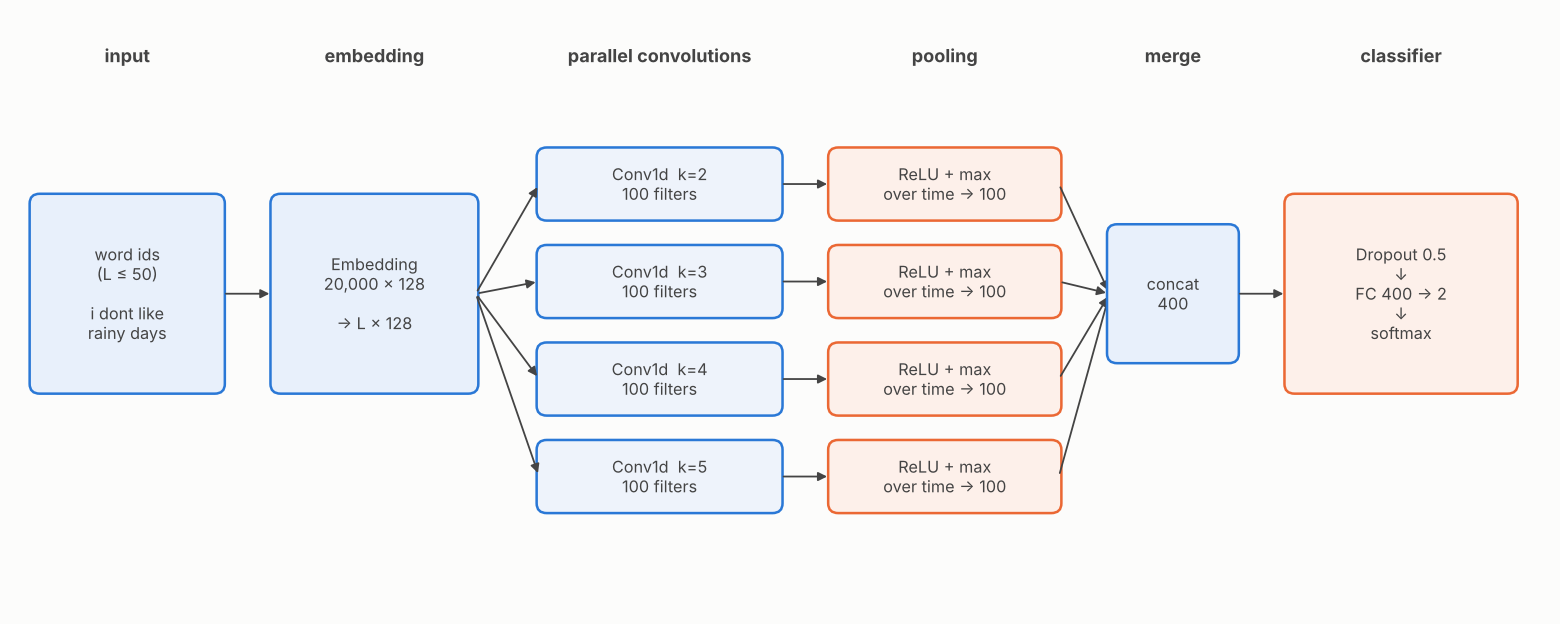

In [2]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

fig, ax = plt.subplots(figsize=(12, 4.8))
ax.set_xlim(0, 12); ax.set_ylim(0, 4.8); ax.axis("off")

def box(x, y, w, h, text, fc="#e8f0fb", ec=BLUE, fs=9):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec=ec, lw=1.4))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs)

def arrow(x1, y1, x2, y2):
    ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle="-|>", mutation_scale=10, color=INK, lw=1.0))

ys = {2: 3.45, 3: 2.65, 4: 1.85, 5: 1.05}     # 四个核宽所在的高度
mid = 2.55

box(0.1, mid - 0.8, 1.5, 1.6, "word ids\n(L ≤ 50)\n\ni dont like\nrainy days")
box(2.0, mid - 0.8, 1.6, 1.6, "Embedding\n20,000 × 128\n\n→ L × 128")
for k, y in ys.items():
    box(4.1, y - 0.28, 1.9, 0.56, f"Conv1d  k={k}\n100 filters", fc="#eef3fb")
    box(6.4, y - 0.28, 1.8, 0.56, "ReLU + max\nover time → 100", fc="#fdf0ea", ec=ORANGE)
    arrow(3.6, mid, 4.1, y); arrow(6.0, y, 6.4, y); arrow(8.2, y, 8.6, mid)
box(8.6, mid - 0.55, 1.0, 1.1, "concat\n400")
box(10.0, mid - 0.8, 1.8, 1.6, "Dropout 0.5\n↓\nFC 400 → 2\n↓\nsoftmax", fc="#fdf0ea", ec=ORANGE)
arrow(1.6, mid, 2.0, mid); arrow(9.6, mid, 10.0, mid)

for x, t in [(0.85, "input"), (2.8, "embedding"), (5.05, "parallel convolutions"),
             (7.3, "pooling"), (9.1, "merge"), (10.9, "classifier")]:
    ax.text(x, 4.45, t, ha="center", fontsize=10, color=INK, weight="bold")
plt.tight_layout(); plt.show()

**参数量**（最终配置，一共 2,740,402）：

| 部分 | 计算 | 参数 |
|---|---|---|
| Embedding | 20,000 × 128 | 2,560,000 |
| 卷积 k=2 / 3 / 4 / 5 | 128 × 100 × k + 100 | 25,700 / 38,500 / 51,300 / 64,100 |
| 全连接 | 400 × 2 + 2 | 802 |

一个实现细节：序列是补零到同一长度的，如果某个卷积窗口覆盖到补零位置，它的输出会被置 0 再做 max pooling，避免补零影响结果（窗口全在补零上时输出 0，所以不会出现 NaN）。下面直接把 `textcnn.py` 里的模型类打印出来，并核对参数量。

In [3]:
src_text = (SRC / "textcnn.py").read_text(encoding="utf-8")
start = src_text.index("class TextCNN")
end = src_text.index("# ----", start)
print(src_text[start:end].rstrip())

emb = 20000 * 128
convs = sum(128 * 100 * k + 100 for k in (2, 3, 4, 5))
fc = 400 * 2 + 2
print("\n参数量核对:", emb, "+", convs, "+", fc, "=", emb + convs + fc)

class TextCNN(nn.Module):
    def __init__(self, vocab_size, emb_dim=128, kernel_sizes=(3, 4, 5), num_filters=100,
                 dropout=0.5, pretrained=None, freeze_emb=False, num_classes=2):
        super().__init__()
        self.kernel_sizes = [int(k) for k in kernel_sizes]
        self.num_filters = num_filters
        self.emb = nn.Embedding(vocab_size, emb_dim, padding_idx=PAD_ID)
        if pretrained is not None:
            self.emb.weight.data.copy_(torch.from_numpy(pretrained))
        self.emb.weight.data[PAD_ID].zero_()
        self.emb.weight.requires_grad = not freeze_emb
        self.convs = nn.ModuleList([nn.Conv1d(emb_dim, num_filters, k) for k in self.kernel_sizes])
        self.drop = nn.Dropout(dropout)
        self.fc = nn.Linear(num_filters * len(self.kernel_sizes), num_classes)

    def features(self, x, lengths):
        """返回每个核宽的卷积激活列表，每项形状 (B, num_filters, L-k+1)。
        窗口只要包含补零位置（i + k > 真实长度）就置 0，避免补零影响 max pooling。"""
        e = self.emb(x).transpo

In [ ]:
# 可选：用 PyTorch 实际建一遍模型核对参数量（需要安装 torch）
try:
    from textcnn import TextCNN
    m = TextCNN(vocab_size=20000, emb_dim=128, kernel_sizes=(2, 3, 4, 5), num_filters=100, dropout=0.5)
    print("TextCNN 实际参数量:", sum(p.numel() for p in m.parameters()))
except ImportError as e:
    print("未安装 torch，跳过：", e)

## 4. 训练设置与运行方式

| 项 | 取值 |
|---|---|
| 优化器 | Adam，学习率 1e-3，**权重衰减 1e-4** |
| 批大小 | 256（同一批内句长相近，减少补零的计算浪费） |
| 最大轮数 / 早停 | 20 轮；验证集准确率连续 2 轮没有提升就停，并**恢复验证集上最好的那一轮的权重** |
| 正则 | Dropout 0.5 + 权重衰减 |
| 评估 | 验证集每轮评估；测试集、人工集只有加 `--eval_test` 才碰 |

**单次训练**（`textcnn.py`）每个种子会写出 `metrics.json`（含每轮曲线）、`val_probs.npy` / `test_probs.npy` / `manual_probs.npy`（预测概率）、`model.pt`；多个种子跑完再写一个 `summary.json`（均值 ± 标准差）。

先用冒烟测试确认环境能跑（1 分钟内，只检查代码不报错）：

In [4]:
if RUN_TRAINING:
    sh("python textcnn.py --data_dir ../../data/tokenized --max_len 50 --subset 5000 --epochs 2 --out runs/smoke")
else:
    print("RUN_TRAINING=False，已跳过。")

RUN_TRAINING=False，已跳过。


## 5. 消融实验（调参只用验证集）

**目的**：回答 “模型里哪些设计真的有用”，并在不碰测试集的前提下选出最终配置。

**做法**：为了省时间，消融阶段只用前 20 万条训练、前 2 万条验证，每个配置跑 **3 个随机种子**，报告均值 ± 标准差。每次只改一个因素（与基准 base 比较）；差异是否可信，用标准差和 McNemar 检验（种子 0 的预测配对比较）判断。

基准 base：核宽 3/4/5、dropout 0.5、词向量 128、100 个滤波器、无权重衰减、句长 50。

**结果（统一预处理，验证集准确率，记录值）**

| 配置 | 准确率 | 与 base 之差 | McNemar p |
|---|---|---|---|
| base | 0.7868 ± 0.0004 | — | — |
| 核宽只用 3 | 0.7816 ± 0.0012 | −0.0052 | < 0.001 |
| **核宽 2/3/4/5** | **0.7936 ± 0.0015** | **+0.0067** | 0.005 |
| 句长 25（减半） | 0.7843 ± 0.0015 | −0.0025 | 0.371 |
| dropout 0.3 | 0.7857 ± 0.0010 | −0.0012 | 0.476 |
| dropout 0.7 | 0.7832 ± 0.0012 | −0.0036 | 0.002 |
| 权重衰减 1e-4（只跑 10 轮，不可靠） | 0.7923 ± 0.0038 | +0.0054 | 0.608 |
| 词向量 64 维 | 0.7852 ± 0.0007 | −0.0016 | 0.681 |
| 滤波器 200 个 | 0.7853 ± 0.0012 | −0.0016 | 0.647 |
| 核宽 2/3/4/5 + 权重衰减 1e-4（20 轮） | 0.8016 ± 0.0010 | +0.0148 | — |

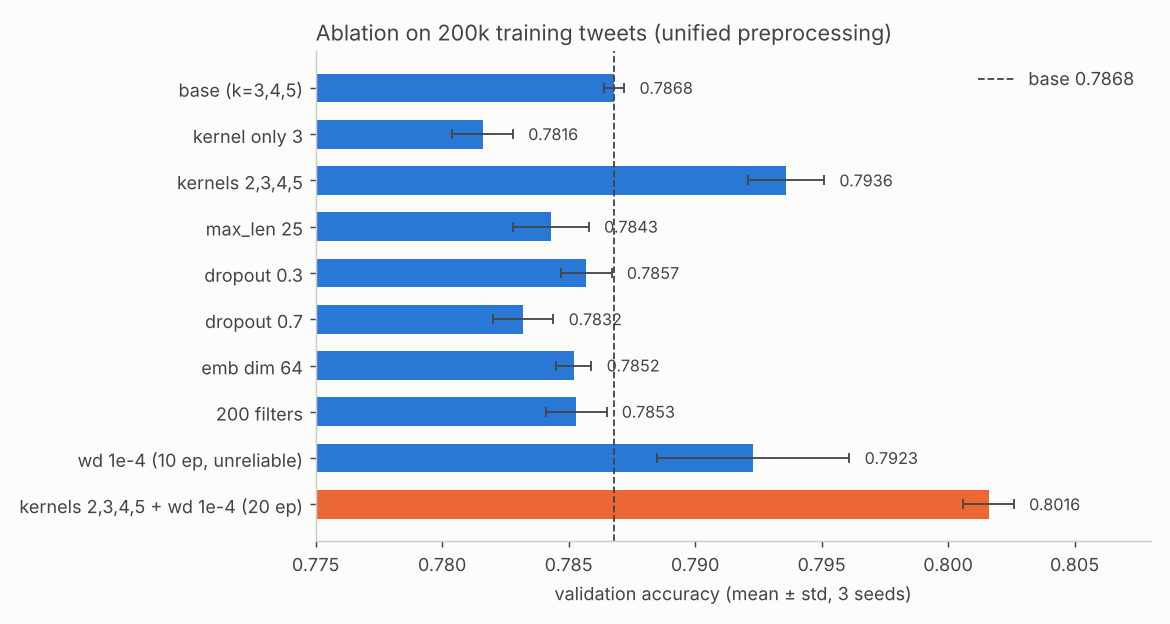

In [5]:
# 消融结果柱状图（记录值：统一预处理，验证集 2 万条，3 个种子；误差棒 = 标准差）
ablation = [  # (标签, 均值, 标准差)
    ("base (k=3,4,5)",                      0.7868, 0.0004),
    ("kernel only 3",                       0.7816, 0.0012),
    ("kernels 2,3,4,5",                     0.7936, 0.0015),
    ("max_len 25",                          0.7843, 0.0015),
    ("dropout 0.3",                         0.7857, 0.0010),
    ("dropout 0.7",                         0.7832, 0.0012),
    ("emb dim 64",                          0.7852, 0.0007),
    ("200 filters",                         0.7853, 0.0012),
    ("wd 1e-4 (10 ep, unreliable)",         0.7923, 0.0038),
    ("kernels 2,3,4,5 + wd 1e-4 (20 ep)",   0.8016, 0.0010),
]
labels = [a[0] for a in ablation][::-1]
means  = np.array([a[1] for a in ablation])[::-1]
stds   = np.array([a[2] for a in ablation])[::-1]
colors = [ORANGE if l.startswith("kernels 2,3,4,5 + wd") else BLUE for l in labels]

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.barh(labels, means, xerr=stds, color=colors, height=0.62, error_kw=dict(ecolor=INK, capsize=3, lw=1))
ax.axvline(0.7868, color=INK, ls="--", lw=1, label="base 0.7868")
ax.legend(frameon=False, loc="upper right")
for i, (m, s) in enumerate(zip(means, stds)):
    ax.text(m + s + 0.0006, i, f"{m:.4f}", va="center", fontsize=9)
ax.set_xlim(0.775, 0.808); ax.set_xlabel("validation accuracy (mean ± std, 3 seeds)")
ax.set_title("Ablation on 200k training tweets (unified preprocessing)", loc="left")
plt.tight_layout(); plt.show()

**怎么解读**（只写数据支持的结论）

- **多种卷积核有用**：加上核宽 2 比 base 高约 0.7 个百分点（p = 0.005）；只用核宽 3 反而显著变差。说明不同长度的短语模式是互补的。
- **容量不是瓶颈**：词向量 64、滤波器 200 都与 base 差不多（差异小于或接近标准差，p 很大）。
- **Dropout 0.7 偏大**（p = 0.002 变差），0.3 与 0.5 没有显著差别，所以保留 0.5。
- **句长影响不大**：减半到 25 只差 0.25 个百分点且不显著（p = 0.371）；训练集 99% 的推文不超过 27 个词，截到 25 影响很小。
- **权重衰减**：10 轮上限那一行波动大（标准差 0.0038）、p = 0.608，**不能据此下结论**，我们因此把轮数放到 20 再比较，“核宽 2/3/4/5 + 权重衰减 1e-4” 达到 0.8016，是 20 万条规模下的最优。在全量数据（128 万训练 / 16 万验证，单种子）上确认：有权重衰减 0.8164，无权重衰减 0.8151，**收益缩小到约 +0.001**，没有做显著性检验，所以最终配置保留它但不夸大它的作用。

最终配置因此定为：**核宽 2/3/4/5（各 100 个）、词向量 128、dropout 0.5、权重衰减 1e-4、20 轮上限 + 早停**。之后不再改动。

重跑消融（耗时较长，需要 GPU；结果写入 `runs/ablation/ablation_summary.csv/.md`）：

In [6]:
if RUN_TRAINING:
    sh("python run_ablations.py --data_dir ../../data/tokenized --out runs/ablation "
       "--seeds 3 --max_len 50 --max_train 200000 --max_val 20000")
    # 最优组合（核宽 2/3/4/5 + 权重衰减 1e-4，20 轮）单独跑：
    sh("python textcnn.py --data_dir ../../data/tokenized --max_len 50 --max_train 200000 --max_val 20000 "
       "--seeds 3 --weight_decay 1e-4 --kernels 2,3,4,5 --epochs 20 --out runs/wd1e-4_k2345")
else:
    print("RUN_TRAINING=False，已跳过。")

RUN_TRAINING=False，已跳过。


## 6. 最终评估（5 个随机种子）

配置固定后，用**全量 128 万条训练集**训练 5 个种子（0–4），在验证集、测试集、人工集上各评估一次。命令（会同时保存每个种子的预测概率和模型权重，供第 7 节分析使用）：

In [7]:
if RUN_TRAINING:
    sh("python textcnn.py --data_dir ../../data/tokenized --max_len 50 --seeds 5 "
       "--weight_decay 1e-4 --kernels 2,3,4,5 --epochs 20 --eval_test --save_model --out runs/final")
else:
    print("RUN_TRAINING=False，已跳过。结果见下方记录值；重跑后可从 runs/final/summary.json 读取。")

RUN_TRAINING=False，已跳过。结果见下方记录值；重跑后可从 runs/final/summary.json 读取。


**最终结果（5 个种子，均值 ± 标准差，记录值）**

| 数据集 | 准确率 | 精确率(正) | 召回率(正) | F1(正) | macro-F1 | AUC |
|---|---|---|---|---|---|---|
| 验证集 16 万 | 0.8163 ± 0.0015 | 0.8179 ± 0.0051 | 0.8138 ± 0.0086 | 0.8158 ± 0.0024 | 0.8163 ± 0.0015 | 0.8965 ± 0.0012 |
| **测试集 16 万** | **0.8166 ± 0.0015** | 0.8170 ± 0.0053 | 0.8160 ± 0.0088 | 0.8165 ± 0.0024 | 0.8166 ± 0.0015 | 0.8973 ± 0.0014 |
| 人工集 359 | 0.8201 ± 0.0133 | 0.7975 ± 0.0146 | 0.8648 ± 0.0138 | 0.8297 ± 0.0122 | 0.8195 ± 0.0134 | 0.9106 ± 0.0074 |

注意区分：**0.8166 是准确率，AUC 是 0.8973**（两个不是一回事）。

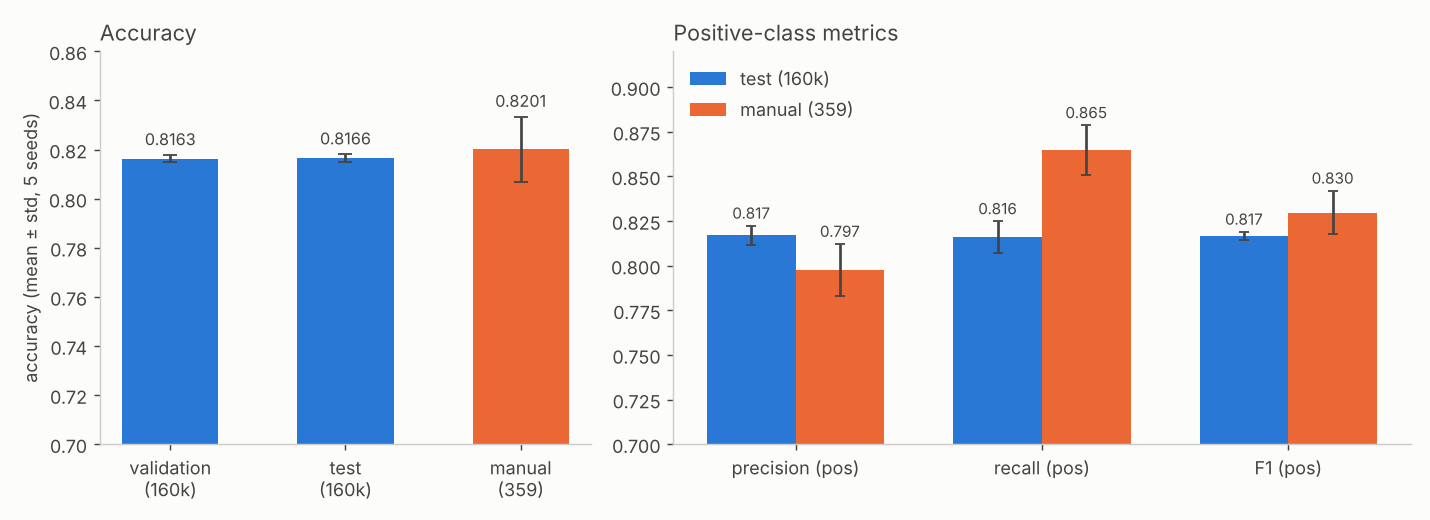

In [8]:
# 记录值（5 个种子的均值, 标准差）
final = {
    "val":    dict(acc=(0.8163, 0.0015), prec=(0.8179, 0.0051), rec=(0.8138, 0.0086), f1=(0.8158, 0.0024)),
    "test":   dict(acc=(0.8166, 0.0015), prec=(0.8170, 0.0053), rec=(0.8160, 0.0088), f1=(0.8165, 0.0024)),
    "manual": dict(acc=(0.8201, 0.0133), prec=(0.7975, 0.0146), rec=(0.8648, 0.0138), f1=(0.8297, 0.0122)),
}
names = {"val": "validation\n(160k)", "test": "test\n(160k)", "manual": "manual\n(359)"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.5]})

ax = axes[0]
sets = ["val", "test", "manual"]
m = [final[s]["acc"][0] for s in sets]; e = [final[s]["acc"][1] for s in sets]
ax.bar([names[s] for s in sets], m, yerr=e, color=[BLUE, BLUE, ORANGE], width=0.55, error_kw=dict(ecolor=INK, capsize=4))
for i, (mm, ee) in enumerate(zip(m, e)):
    ax.text(i, mm + ee + 0.004, f"{mm:.4f}", ha="center", fontsize=9)
ax.set_ylim(0.70, 0.86); ax.set_ylabel("accuracy (mean ± std, 5 seeds)")
ax.set_title("Accuracy", loc="left")

ax = axes[1]
mets = [("prec", "precision (pos)"), ("rec", "recall (pos)"), ("f1", "F1 (pos)")]
x = np.arange(len(mets)); w = 0.36
for j, (s, c, lab) in enumerate([("test", BLUE, "test (160k)"), ("manual", ORANGE, "manual (359)")]):
    mm = [final[s][k][0] for k, _ in mets]; ee = [final[s][k][1] for k, _ in mets]
    bars = ax.bar(x + (j - 0.5) * w, mm, w, yerr=ee, color=c, label=lab, error_kw=dict(ecolor=INK, capsize=3))
    for r, v, sd in zip(bars, mm, ee):
        ax.text(r.get_x() + r.get_width()/2, v + sd + 0.004, f"{v:.3f}", ha="center", fontsize=8.5)
ax.set_xticks(x); ax.set_xticklabels([n for _, n in mets]); ax.set_ylim(0.70, 0.92)
ax.legend(frameon=False, loc="upper left"); ax.set_title("Positive-class metrics", loc="left")
plt.tight_layout(); plt.show()

**怎么解读**

- **验证集与测试集几乎一样**（0.8163 vs 0.8166）：没有对验证集过拟合，说明“调参只看验证集”的流程是干净的。测试集上正/负两类的精确率和召回率也很对称。
- **种子间波动很小**（标准差 0.0015），所以小于 0.003 左右的差异不应当被当作真实差别。
- **人工集（359 条）准确率 0.8201，不能说它比测试集更高**：样本太少，准确率的误差范围约 ±4 个百分点，标准差 0.0133 也只是种子间波动。它值得注意的是**正类召回率 0.865 高于负类召回率 0.774**，模型对“正面”略偏，原因见第 7 节（样本少，只能作为迹象）。

**训练曲线（种子 0）**：下图是 `analyze.py` 生成的损失和准确率曲线，竖线为最佳轮次（第 11 轮，之后连续 2 轮没有提升，第 13 轮停止；5 个种子的最佳轮次依次为 11、7、5、11、11）。训练集的数值低于验证集，是因为训练指标是在 dropout 开启的状态下、整轮取平均得到的；验证集评估时 dropout 关闭、用的是轮末的权重。训练和验证两条曲线很接近，没有出现验证变差的过拟合迹象。

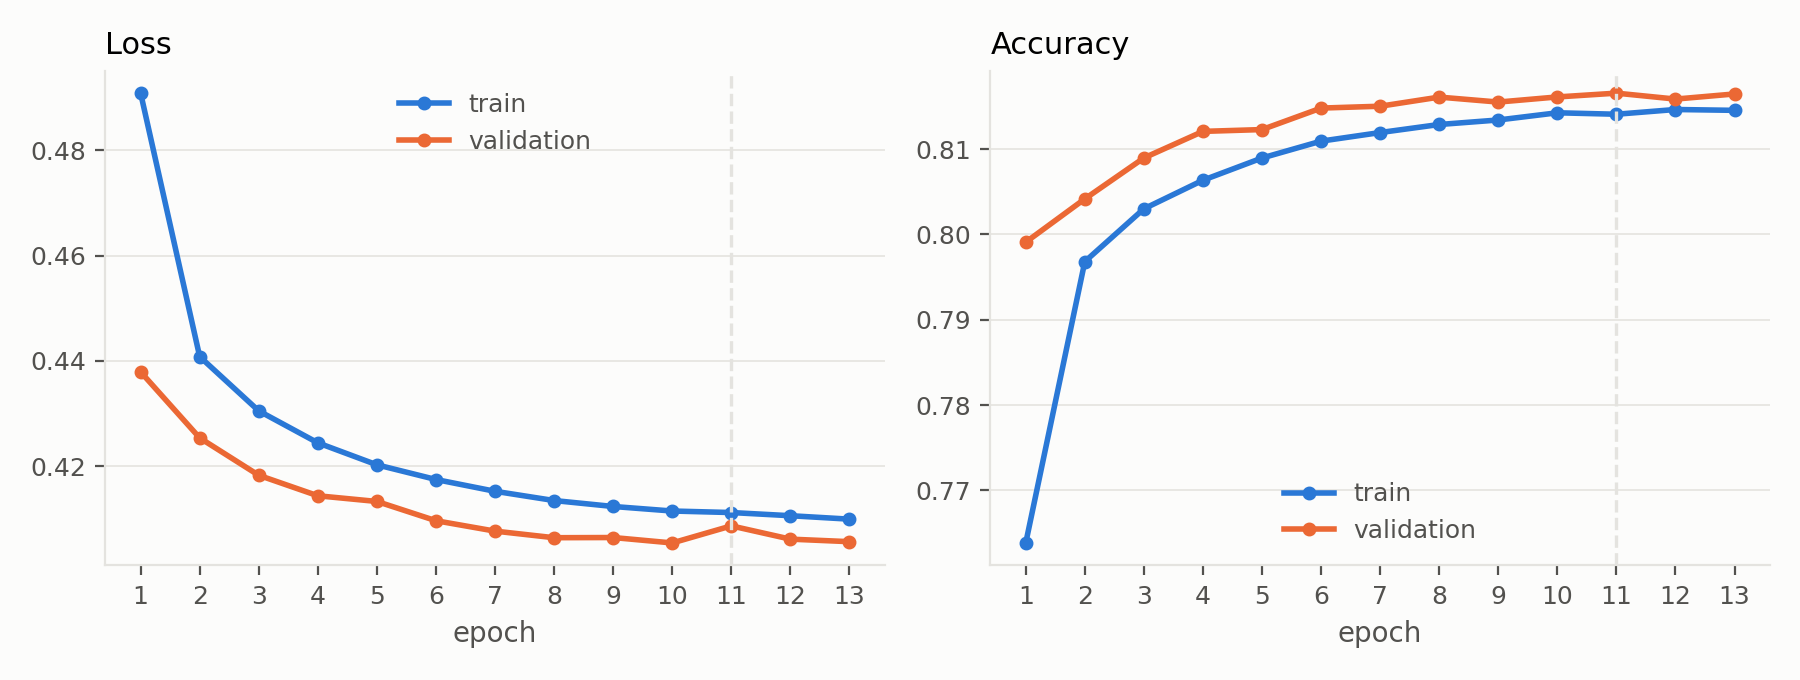

## 7. 误差分析

以下用种子 0 的预测。**文中的错误分类是人工判断**，引用到报告前建议再抽查。生成这些图和表的命令：

In [9]:
if RUN_TRAINING:
    for split in ("test", "manual"):
        sh(f"python analyze.py --run_dir runs/final/seed0 --data_dir ../../data/tokenized "
           f"--csv_dir ../../data/processed --split {split} --ngrams")
    # 输出在 runs/final/seed0/analysis_test/ 与 analysis_manual/：
    #   curves.png  confusion.png  by_length.png/.csv  errors.csv  ngrams.csv/.md  metrics_{split}.json
else:
    print("RUN_TRAINING=False，已跳过。下面的图是我们之前跑出的结果。")

RUN_TRAINING=False，已跳过。下面的图是我们之前跑出的结果。


### 7.1 混淆矩阵（种子 0）

左：测试集 16 万条；右：人工集 359 条。每格是条数和占该真实类别的比例。

| 测试集 | 人工集 |
|---|---|
| 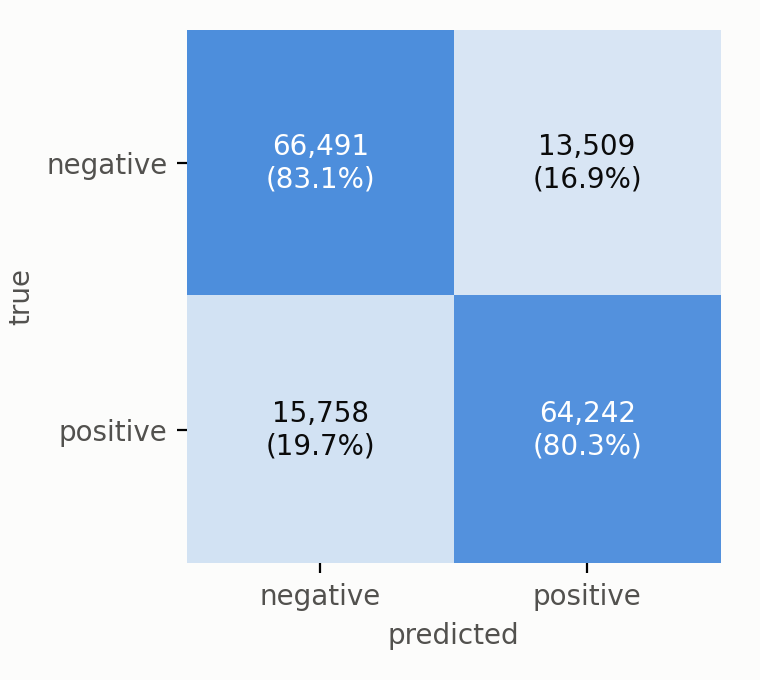 | 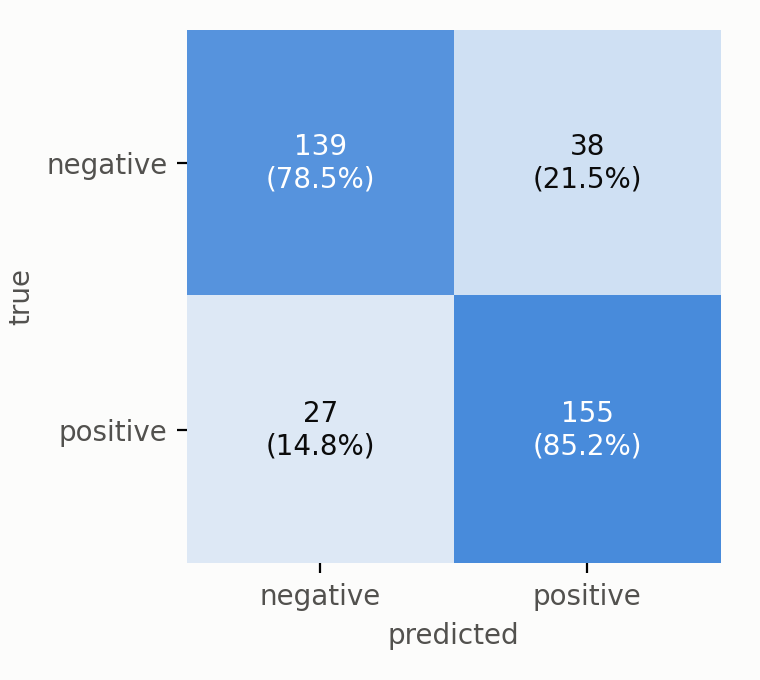 |

- 测试集：负面召回 83.1%、正面召回 80.3%，错 29,267 条（准确率 0.8171），两类基本对称。
- 人工集：负面召回只有 78.5%（把 38 条负面判成正面），正面召回 85.2%，错 65 条（准确率 0.8189）。对应第 6 节的“正类召回率 > 负类召回率”。

### 7.2 按句长看准确率

| 测试集（16 万条） | 人工集（359 条） |
|---|---|
| 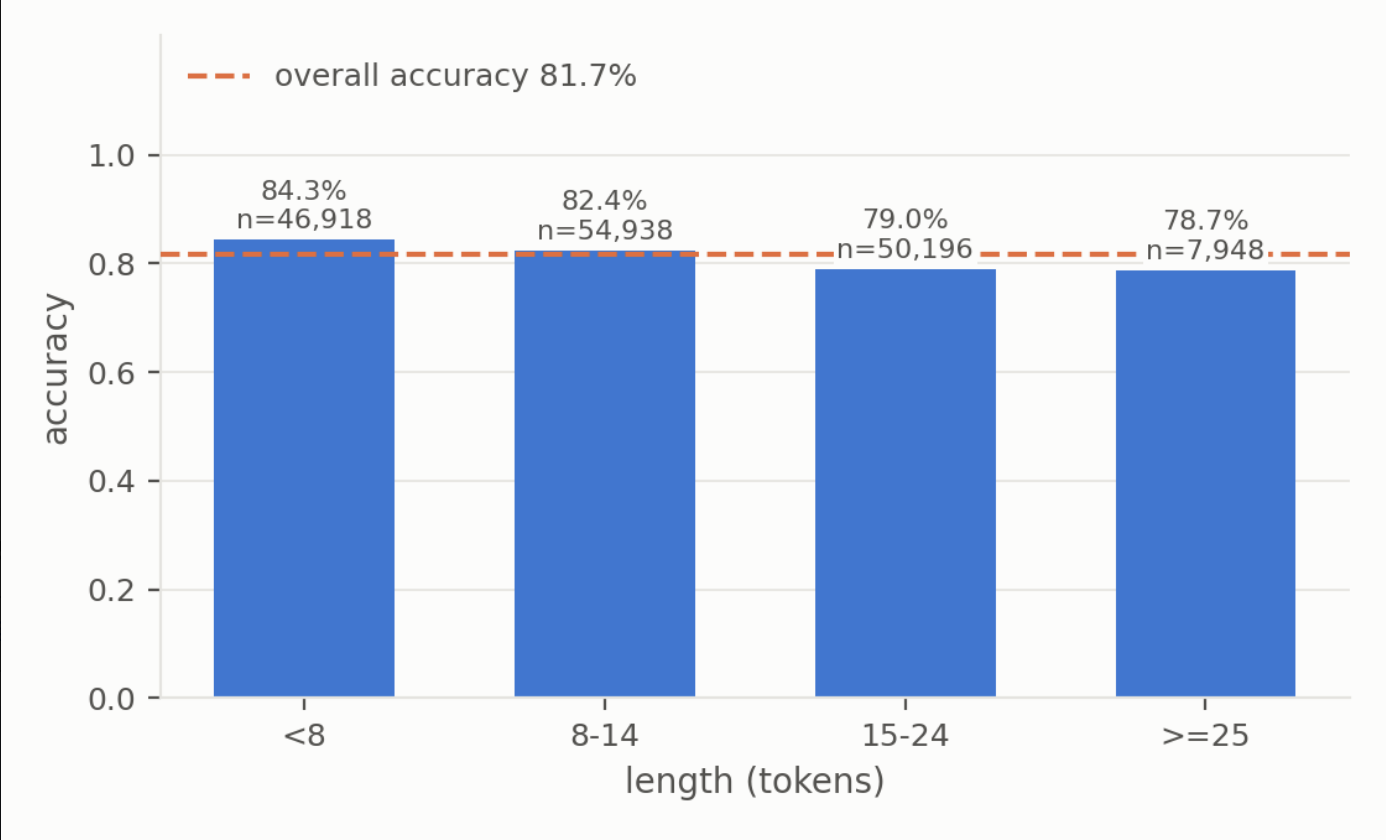 | 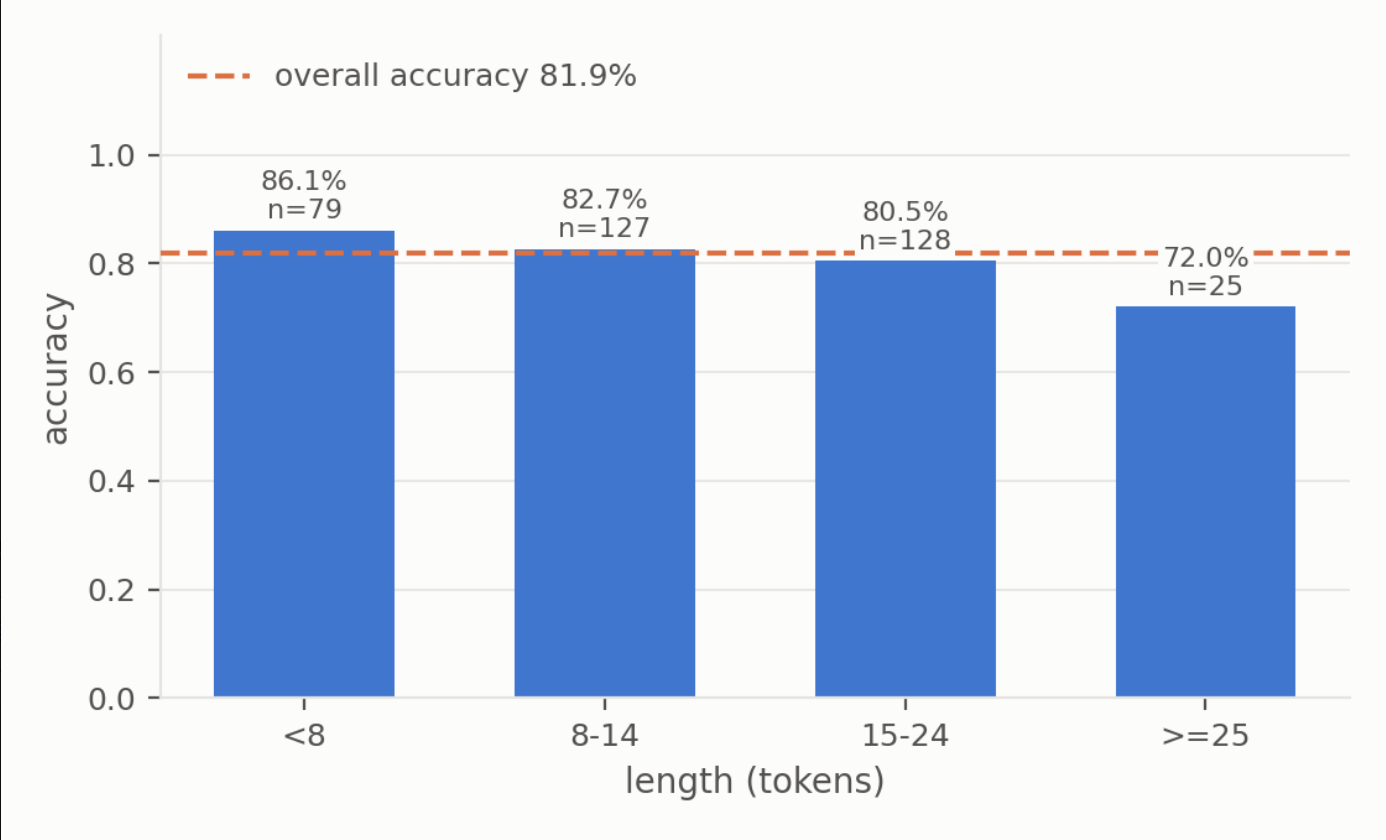 |

测试集上，**句子越长越难**：<8 个词 0.843；8–14 个词 0.824；15–24 个词 0.790；≥25 个词 0.787。一个可能的原因是长推文更容易同时包含正负情绪（这是推测，没有单独验证）。人工集趋势相近但每组只有几十到一百多条（≥25 词只有 25 条），波动很大，不宜解读。

（这两张图来自我们的截图，原图在重跑 `analyze.py` 后位于各自的 `analysis_*/by_length.png`。）

### 7.3 测试集：错误主要是标签噪声

我们看了模型**最自信却判错**的 50 条（预测概率 ≤ 0.01 或 ≥ 0.99，属极端情况，不代表全部错误）。其中 46 条是“标签为正、模型判负”，4 条反过来。人工归类：

| 类别 | 条数 | 说明 |
|---|---|---|
| 标签为正，但文字明显负面（sad、lonely、depressing、hate…） | 27 | 标签与文字不一致，**模型判断合理** |
| 混合/关切/思念类情绪（miss、condolences、praying、“excited… sad that…”） | 11 | 本身就难分 |
| 标签为负，但文字明显正面（如 “have a great time in maui”） | 4 | 标签错，模型是对的 |
| 中性或信息太少（如 “She can't. She has dentist.”） | 6 | 没有情感线索 |
| 看起来是模型自身缺陷 | 2 | “isn't going to put a downer on my day”（否定负面词）、“tired… btw happy momma day”（先抑后扬） |

**结论**：这 50 条里至多约 2 条是模型能力问题，其余主要来自 Sentiment140 的**远程监督标签噪声**（标签来自表情符号，表情符号和文字情绪并不总是一致，且训练文本里表情符号已被删，模型看不到标签的来源）。这也意味着在这份数据上，准确率有一个远低于 100% 的天花板，不能单看分数判断模型好坏。

### 7.4 卷积核学到了什么（验证集上每个滤波器最敏感的词组）

对保存的模型，找出让各个滤波器激活最强的 n-gram（`analyze.py --ngrams`）：

- **偏正面的滤波器**：`isnt awful`、`if not bad`、`not bad not bad`、`hopefully not no need`、`if no rain`、`haha no no its not` → 规律是 “**否定词 + 负面词**”。
- **偏负面的滤波器**：`isnt happy`、`not feeling happy`、`isnt feeling good`、`no good no good`、`why r all good` → “**否定词 + 正面词**”。
- 说明卷积窗口学到了局部的**否定模式**，这与消融里 “多种核宽更好” 一致（短语长度不同，模式也不同）。
- 也有数据特有的痕迹：某个偏负面的滤波器对 `air france im hoping` 敏感——数据集是 2009 年 4–6 月的推文，对应 2009 年 6 月的法航空难。这类“话题词”是数据集特有的，换到别的时间段不一定成立。

### 7.5 人工测试集：错误来自“对象”和“语体”不同

人工集（359 条）错 65 条（误判为正 38、误判为负 27）。看模型最自信的 50 条错误（概率 0.03–0.96，比测试集温和得多），人工归类：

| 类别 | 条数 | 例子/说明 |
|---|---|---|
| **针对对象的批评、讽刺、反问**，文字里没有明显情感词 | 15 | Time Warner 的口号、“Cheney needs to shut…”、“Tell me again why we are giving more $$ to GM??” |
| 混合情绪 / 先扬后抑 / 多对象 | 11 | “Star Trek was amazing, but Night at the Museum was; eh” |
| **表情符号被预处理丢弃**，而表情符号恰好指向正确标签 | 6 | `:(`、`:/`、`:-(`、`=]`、`:)` |
| 俚语、粗口、拼写变体、语境词压过情感词 | 11 | “LeBron is a monsta/beast/MURDERING”、“furious with time warner” 判为正 |
| 中性/信息太少、怀旧想念类、标签可疑 | 7 | |

**解读（推断，未验证）**：人工集是围绕公司、人物、政治、电影等关键词收集的，标签是对**某个对象的态度**；而训练集的负面推文大多是**个人情绪表达**（sad、miss、hate…）。模型把没有情感词的批评判成正面，所以负类召回率（0.774）比正类（0.865）低。另外人工集保留了表情符号，训练集没有，也构成分布差异。再次强调：样本只有 359 条，以上只能作为迹象。

## 8. 结论与局限

**主要结论**

- 最终 TextCNN（核宽 2/3/4/5 + 权重衰减 1e-4，128 万条训练）在测试集上准确率 **0.8166 ± 0.0015**，AUC 0.8973；验证/测试几乎一致，没有过拟合验证集。
- 消融表明**多种卷积核**是最明确的收益（+0.7 个百分点，显著）；词向量维度、滤波器数量不是瓶颈；dropout 0.7 偏大；权重衰减在全量数据上收益只有约 0.1 个百分点。
- 误差分析：测试集的错误大量来自标签噪声；人工集的错误更多来自“针对对象的态度”“表情符号”“俚语”，说明**训练分布与外部分布有差异**。

**局限**

- 组内统一预处理丢掉了 `!`、`?`、表情符号和数字（为了跨模型对齐），这会限制 TextCNN，误差分析里与表情符号相关的错误即来自这里。
- 词向量是随机初始化；没有试预训练词向量（如 GloVe Twitter），而误差分析显示俚语和词汇覆盖是弱点之一，这是一个自然的后续实验（本 notebook 未包含；`textcnn.py` 已支持 `--glove`）。
- 人工集只有 359 条，结论只能作为迹象；错误类别是人工判断，数量不大。
- 消融用 20 万条训练规模做，全量数据上的最优配置可能略有不同（权重衰减的收益缩小就是一个例子）。

**本目录文件**

```
textcnn.py          模型 + 训练 + 评估（多种子、早停、可选 GloVe）
tc_utils.py         指标、数据读取、随机种子等通用函数
run_ablations.py    消融实验
analyze.py          曲线、混淆矩阵、按句长准确率、错误样本、滤波器最强 n-gram
results/            最终结果（RESULTS.md）与图（figures/）
```